**NOTEBOOK 1: Multinomial Logistic Regression Comparison**

 Comparing 4 configurations:
   1. SMOTE + with total_exp
   2. SMOTE + without total_exp
   3. Class weights + with total_exp
   4. Class weights + without total_exp

**1. Setup**

In [16]:
# Install dependencies first: pip install -r requirements.txt
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, accuracy_score, roc_auc_score
)
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

**Load the dataset**

In [17]:
# Load the modeling dataset (created by 01_data_pipeline.Rmd)
df = pd.read_csv('data/processed/final_for_modeling.csv')

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

# Fix the hosp_class_label column
df['hosp_class_label'] = df['hosp_class'].map({0: 'None', 1: 'Single', 2: 'Multiple'})

print(f"\nClass distribution:")
print(df['hosp_class_label'].value_counts())
print(f"\nImbalance ratio (None : Multiple) = {df['hosp_class_label'].value_counts()['None'] / df['hosp_class_label'].value_counts()['Multiple']:.0f}:1")

Loaded 53,140 rows and 28 columns

Class distribution:
hosp_class_label
None        48690
Single       3533
Multiple      917
Name: count, dtype: int64

Imbalance ratio (None : Multiple) = 53:1


**Define feature groups and clean the data**

In [18]:
# --- Feature definitions ---

# Columns to drop (not predictors)
drop_cols = ['DUPERSID', 'panel', 'hospitalized', 'hosp_class', 'hosp_class_label']

# Nominal categoricals - one-hot encode
nominal_cols = ['race', 'region', 'insurance']

# Ordinal categoricals - map to numbers
ordinal_cols = ['health_status', 'mental_health', 'poverty_cat']

# Binary (already 0/1)
binary_cols = ['female', 'married', 'employed', 'has_limitation',
               'has_diabetes', 'has_hypertension', 'has_heart_disease',
               'has_copd', 'has_depression', 'has_arthritis', 'has_stroke',
               'polypharmacy']

# Continuous
numerical_cols = ['age', 'er_visits', 'total_exp', 'num_conditions', 'num_unique_meds']

# --- Encode ordinals ---
df['health_status_num'] = df['health_status'].map({
    'Excellent': 1, 'Very Good': 2, 'Good': 3, 'Fair': 4, 'Poor': 5
})
df['mental_health_num'] = df['mental_health'].map({
    'Excellent': 1, 'Very Good': 2, 'Good': 3, 'Fair': 4, 'Poor': 5
})
df['poverty_cat_num'] = df['poverty_cat'].map({
    'High Income': 1, 'Middle Income': 2, 'Low Income': 3, 'Near Poor': 4, 'Poor': 5
})

# --- One-hot encode nominals ---
df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)

# --- Drop rows with missing values ---
all_features = binary_cols + numerical_cols + ['health_status_num', 'mental_health_num', 'poverty_cat_num']
dummy_cols = [c for c in df_encoded.columns if any(c.startswith(n + '_') for n in nominal_cols)]
all_features += dummy_cols

n_before = len(df_encoded)
df_clean = df_encoded.dropna(subset=all_features).copy()
n_after = len(df_clean)

print(f"Before cleaning: {n_before:,}")
print(f"After cleaning:  {n_after:,}")
print(f"Dropped {n_before - n_after:,} rows ({(n_before - n_after)/n_before*100:.1f}%)")

Before cleaning: 53,140
After cleaning:  50,733
Dropped 2,407 rows (4.5%)


**Build feature matrices - two versions (with and without total_exp)**

In [19]:
# We split into the two feature sets for the leakage comparison (with and without total_exp)

# Columns to drop from the encoded dataframe
to_drop = drop_cols + ordinal_cols
to_drop = [c for c in to_drop if c in df_clean.columns]

# Version 1: ALL features (including total_exp)
X_full = df_clean.drop(columns=to_drop)
print(f"Full feature set: {X_full.shape[1]} features")

# Version 2: WITHOUT total_exp (addressing leakage concern)
X_no_exp = X_full.drop(columns=['total_exp'])
print(f"Without total_exp: {X_no_exp.shape[1]} features")

# Target variable (same for both)
y = df_clean['hosp_class_label']

print(f"\nTotal observations: {len(y):,}")
print(f"\nClass distribution:")
print(y.value_counts())

Full feature set: 27 features
Without total_exp: 26 features

Total observations: 50,733

Class distribution:
hosp_class_label
None        46593
Single       3306
Multiple      834
Name: count, dtype: int64


**Train-test split for both versions**

In [20]:
#  Train-test split (same split for both feature sets)

X_full_train, X_full_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, random_state=42, stratify=y
)

# Use the same indices for the no-total_exp version
X_no_exp_train = X_no_exp.loc[X_full_train.index]
X_no_exp_test = X_no_exp.loc[X_full_test.index]

print(f"Train: {X_full_train.shape[0]:,}  |  Test: {X_full_test.shape[0]:,}")
print(f"\nTraining distribution:")
print(y_train.value_counts())
print(f"\nTest distribution:")
print(y_test.value_counts())

Train: 40,586  |  Test: 10,147

Training distribution:
hosp_class_label
None        37274
Single       2645
Multiple      667
Name: count, dtype: int64

Test distribution:
hosp_class_label
None        9319
Single       661
Multiple     167
Name: count, dtype: int64


**Scaling function**

In [21]:
def scale_features(X_train, X_test, has_total_exp=True):
    """Scale numerical and ordinal columns. Returns scaled copies."""

    cols_to_scale = ['age', 'er_visits', 'num_conditions', 'num_unique_meds',
                     'health_status_num', 'mental_health_num', 'poverty_cat_num']

    if has_total_exp:
        cols_to_scale.append('total_exp')

    scaler = StandardScaler()

    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
    X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

    return X_train_scaled, X_test_scaled

print("Scaling function ready")

Scaling function ready


**Evaluation function**

In [22]:
# --- Evaluation function ---

def evaluate_config(X_train, X_test, y_train, y_test, config_name,
                    use_smote=True, use_class_weight=False):
    """
    Train and evaluate one logistic regression configuration.
    Returns a dictionary of metrics.
    """

    # Step 1: Handle class imbalance
    if use_smote:
        smote = SMOTE(random_state=42, k_neighbors=5)
        X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
        weight_param = None
    elif use_class_weight:
        X_train_bal, y_train_bal = X_train, y_train
        weight_param = 'balanced'
    else:
        X_train_bal, y_train_bal = X_train, y_train
        weight_param = None

    # Step 2: Train model
    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        multi_class='multinomial',
        C=1.0,
        l1_ratio=0.5,
        max_iter=5000,
        random_state=42,
        class_weight=weight_param,
        n_jobs=-1
    )
    model.fit(X_train_bal, y_train_bal)

    # Step 3: Predict
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)

    # Step 4: Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    model_classes = list(model.classes_)
    y_test_bin = label_binarize(y_test, classes=model_classes)
    macro_auc = roc_auc_score(y_test_bin, y_pred_proba, multi_class='ovr', average='macro')

    # Per-class metrics
    f1_each = f1_score(y_test, y_pred, average=None, labels=model_classes)
    prec_each = precision_score(y_test, y_pred, average=None, labels=model_classes)
    rec_each = recall_score(y_test, y_pred, average=None, labels=model_classes)

    # Step 5: Store everything
    results = {
        'config': config_name,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'macro_auc': macro_auc,
        'model': model,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'classes': model_classes
    }

    # Add per-class metrics
    for i, cls in enumerate(model_classes):
        results[f'{cls}_precision'] = prec_each[i]
        results[f'{cls}_recall'] = rec_each[i]
        results[f'{cls}_f1'] = f1_each[i]

    print(f"\n{'='*55}")
    print(f"Config: {config_name}")
    print(f"{'='*55}")
    print(f"  Accuracy:    {acc:.4f}")
    print(f"  Macro F1:    {macro_f1:.4f}")
    print(f"  Weighted F1: {weighted_f1:.4f}")
    print(f"  Macro AUC:   {macro_auc:.4f}")
    for i, cls in enumerate(model_classes):
        print(f"  {cls:10s}  P={prec_each[i]:.4f}  R={rec_each[i]:.4f}  F1={f1_each[i]:.4f}")

    return results

print("Evaluation function ready")

Evaluation function ready


**Running all 4 configurations**

In [23]:
results_list = []

# Config 1: SMOTE + with total_exp
print("Running Config 1 of 4...")
X_tr_scaled, X_te_scaled = scale_features(X_full_train, X_full_test, has_total_exp=True)
r1 = evaluate_config(X_tr_scaled, X_te_scaled, y_train, y_test,
                     config_name="SMOTE + total_exp",
                     use_smote=True, use_class_weight=False)
results_list.append(r1)

# Config 2: SMOTE + without total_exp
print("\nRunning Config 2 of 4...")
X_tr_scaled, X_te_scaled = scale_features(X_no_exp_train, X_no_exp_test, has_total_exp=False)
r2 = evaluate_config(X_tr_scaled, X_te_scaled, y_train, y_test,
                     config_name="SMOTE + no total_exp",
                     use_smote=True, use_class_weight=False)
results_list.append(r2)

# Config 3: Class weights + with total_exp
print("\nRunning Config 3 of 4...")
X_tr_scaled, X_te_scaled = scale_features(X_full_train, X_full_test, has_total_exp=True)
r3 = evaluate_config(X_tr_scaled, X_te_scaled, y_train, y_test,
                     config_name="Weighted + total_exp",
                     use_smote=False, use_class_weight=True)
results_list.append(r3)

# Config 4: Class weights + without total_exp
print("\nRunning Config 4 of 4...")
X_tr_scaled, X_te_scaled = scale_features(X_no_exp_train, X_no_exp_test, has_total_exp=False)
r4 = evaluate_config(X_tr_scaled, X_te_scaled, y_train, y_test,
                     config_name="Weighted + no total_exp",
                     use_smote=False, use_class_weight=True)
results_list.append(r4)

Running Config 1 of 4...

Config: SMOTE + total_exp
  Accuracy:    0.9112
  Macro F1:    0.6294
  Weighted F1: 0.9197
  Macro AUC:   0.9231
  Multiple    P=0.3905  R=0.4910  F1=0.4350
  None        P=0.9782  R=0.9397  F1=0.9586
  Single      P=0.4132  R=0.6157  F1=0.4945

Running Config 2 of 4...

Config: SMOTE + no total_exp
  Accuracy:    0.8197
  Macro F1:    0.4610
  Weighted F1: 0.8492
  Macro AUC:   0.7627
  Multiple    P=0.1963  R=0.3832  F1=0.2596
  None        P=0.9519  R=0.8616  F1=0.9045
  Single      P=0.1616  R=0.3389  F1=0.2189

Running Config 3 of 4...

Config: Weighted + total_exp
  Accuracy:    0.8827
  Macro F1:    0.5901
  Weighted F1: 0.9027
  Macro AUC:   0.9380
  Multiple    P=0.2753  R=0.6347  F1=0.3841
  None        P=0.9878  R=0.9051  F1=0.9447
  Single      P=0.3401  R=0.6293  F1=0.4416

Running Config 4 of 4...

Config: Weighted + no total_exp
  Accuracy:    0.7299
  Macro F1:    0.4096
  Weighted F1: 0.7962
  Macro AUC:   0.8071
  Multiple    P=0.1097  R=0.6

**Comparison table**

In [24]:
comparison_df = pd.DataFrame({
    'Configuration': [r['config'] for r in results_list],
    'Accuracy': [r['accuracy'] for r in results_list],
    'Macro F1': [r['macro_f1'] for r in results_list],
    'Weighted F1': [r['weighted_f1'] for r in results_list],
    'Macro AUC': [r['macro_auc'] for r in results_list],
    'Multiple F1': [r['Multiple_f1'] for r in results_list],
    'Single F1': [r['Single_f1'] for r in results_list],
    'None F1': [r['None_f1'] for r in results_list],
    'Multiple Recall': [r['Multiple_recall'] for r in results_list],
    'Single Recall': [r['Single_recall'] for r in results_list],
})

# Round everything to 4 decimal places
comparison_df = comparison_df.round(4)

print("=" * 80)
print("LOGISTIC REGRESSION: 4-WAY COMPARISON")
print("=" * 80)
print(comparison_df.to_string(index=False))

LOGISTIC REGRESSION: 4-WAY COMPARISON
          Configuration  Accuracy  Macro F1  Weighted F1  Macro AUC  Multiple F1  Single F1  None F1  Multiple Recall  Single Recall
      SMOTE + total_exp    0.9112    0.6294       0.9197     0.9231       0.4350     0.4945   0.9586           0.4910         0.6157
   SMOTE + no total_exp    0.8197    0.4610       0.8492     0.7627       0.2596     0.2189   0.9045           0.3832         0.3389
   Weighted + total_exp    0.8827    0.5901       0.9027     0.9380       0.3841     0.4416   0.9447           0.6347         0.6293
Weighted + no total_exp    0.7299    0.4096       0.7962     0.8071       0.1868     0.1921   0.8499           0.6287         0.3737


**Comparison visualization**

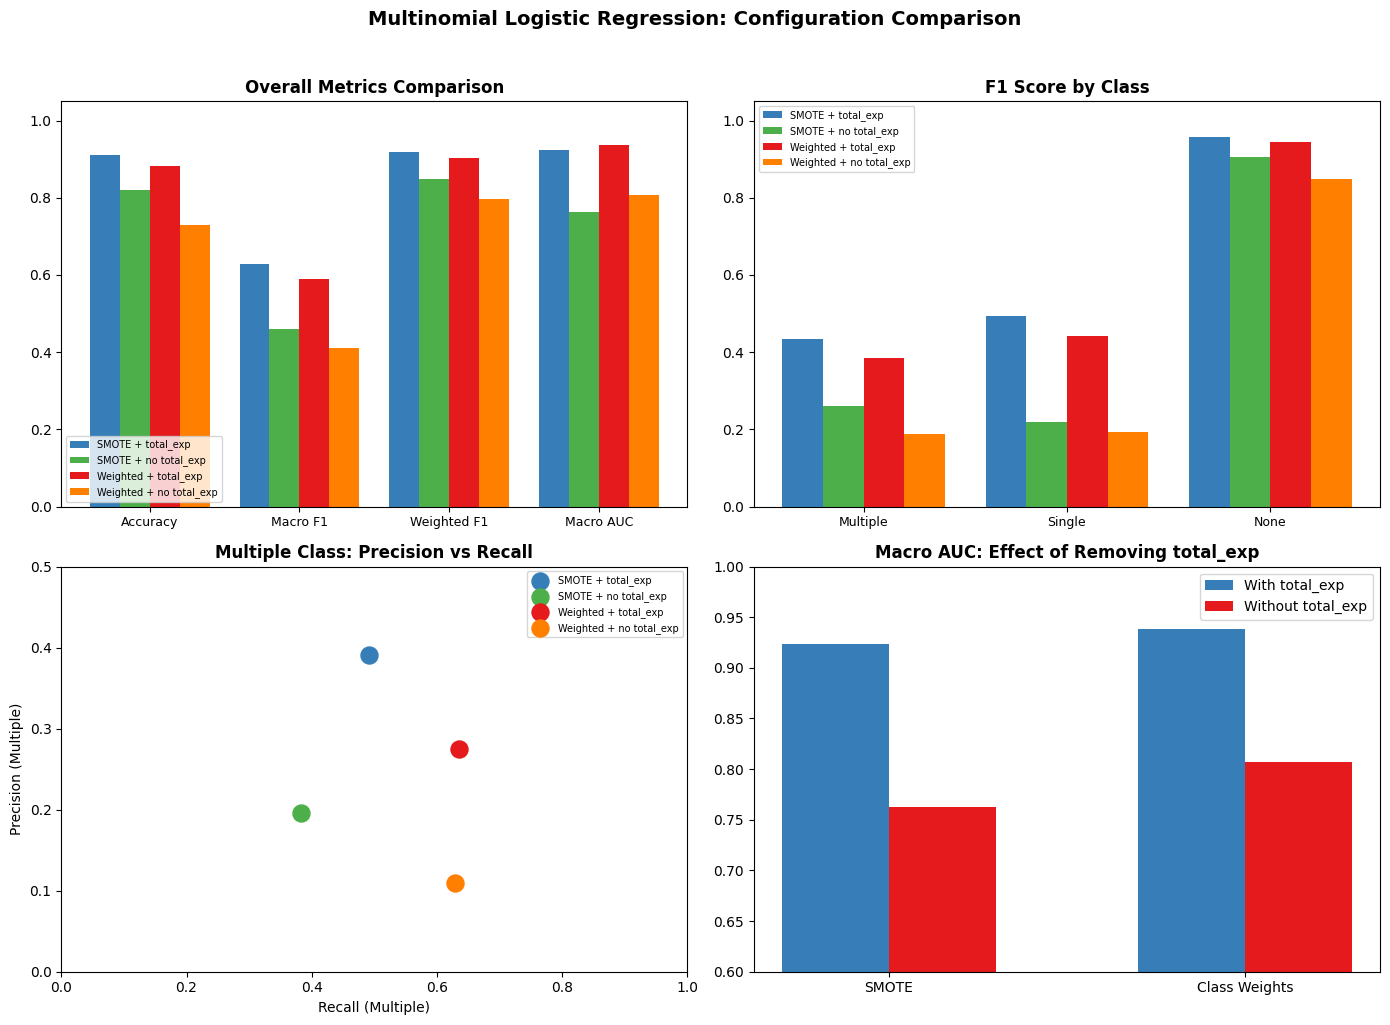

In [25]:
# --- Visual comparison of the 4 configurations ---

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Overall metrics
metrics = ['Accuracy', 'Macro F1', 'Weighted F1', 'Macro AUC']
x = np.arange(len(metrics))
width = 0.2
configs = comparison_df['Configuration'].tolist()
colors = ['#377EB8', '#4DAF4A', '#E41A1C', '#FF7F00']

for i, config in enumerate(configs):
    values = comparison_df[comparison_df['Configuration'] == config][metrics].values[0]
    axes[0,0].bar(x + i*width, values, width, label=config, color=colors[i])

axes[0,0].set_xticks(x + 1.5*width)
axes[0,0].set_xticklabels(metrics, fontsize=9)
axes[0,0].set_title('Overall Metrics Comparison', fontweight='bold')
axes[0,0].set_ylim(0, 1.05)
axes[0,0].legend(fontsize=7, loc='lower left')

# Plot 2: Per-class F1 scores
class_f1 = ['Multiple F1', 'Single F1', 'None F1']
x2 = np.arange(len(class_f1))

for i, config in enumerate(configs):
    values = comparison_df[comparison_df['Configuration'] == config][class_f1].values[0]
    axes[0,1].bar(x2 + i*width, values, width, label=config, color=colors[i])

axes[0,1].set_xticks(x2 + 1.5*width)
axes[0,1].set_xticklabels(['Multiple', 'Single', 'None'], fontsize=9)
axes[0,1].set_title('F1 Score by Class', fontweight='bold')
axes[0,1].set_ylim(0, 1.05)
axes[0,1].legend(fontsize=7)

# Plot 3: Multiple class - Precision vs Recall tradeoff
mult_prec = [r['Multiple_precision'] for r in results_list]
mult_rec = [r['Multiple_recall'] for r in results_list]

for i, config in enumerate(configs):
    axes[1,0].scatter(mult_rec[i], mult_prec[i], s=150, color=colors[i],
                      label=config, zorder=5)

axes[1,0].set_xlabel('Recall (Multiple)')
axes[1,0].set_ylabel('Precision (Multiple)')
axes[1,0].set_title('Multiple Class: Precision vs Recall', fontweight='bold')
axes[1,0].legend(fontsize=7)
axes[1,0].set_xlim(0, 1)
axes[1,0].set_ylim(0, 0.5)

# Plot 4: Impact of removing total_exp (AUC comparison)
auc_data = {
    'SMOTE': [results_list[0]['macro_auc'], results_list[1]['macro_auc']],
    'Class Weights': [results_list[2]['macro_auc'], results_list[3]['macro_auc']]
}
x3 = np.arange(2)
axes[1,1].bar(x3 - 0.15, [auc_data['SMOTE'][0], auc_data['Class Weights'][0]],
              0.3, label='With total_exp', color='#377EB8')
axes[1,1].bar(x3 + 0.15, [auc_data['SMOTE'][1], auc_data['Class Weights'][1]],
              0.3, label='Without total_exp', color='#E41A1C')
axes[1,1].set_xticks(x3)
axes[1,1].set_xticklabels(['SMOTE', 'Class Weights'])
axes[1,1].set_title('Macro AUC: Effect of Removing total_exp', fontweight='bold')
axes[1,1].set_ylim(0.6, 1.0)
axes[1,1].legend()

plt.suptitle('Multinomial Logistic Regression: Configuration Comparison',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Confusion matrices for all 4 configs**

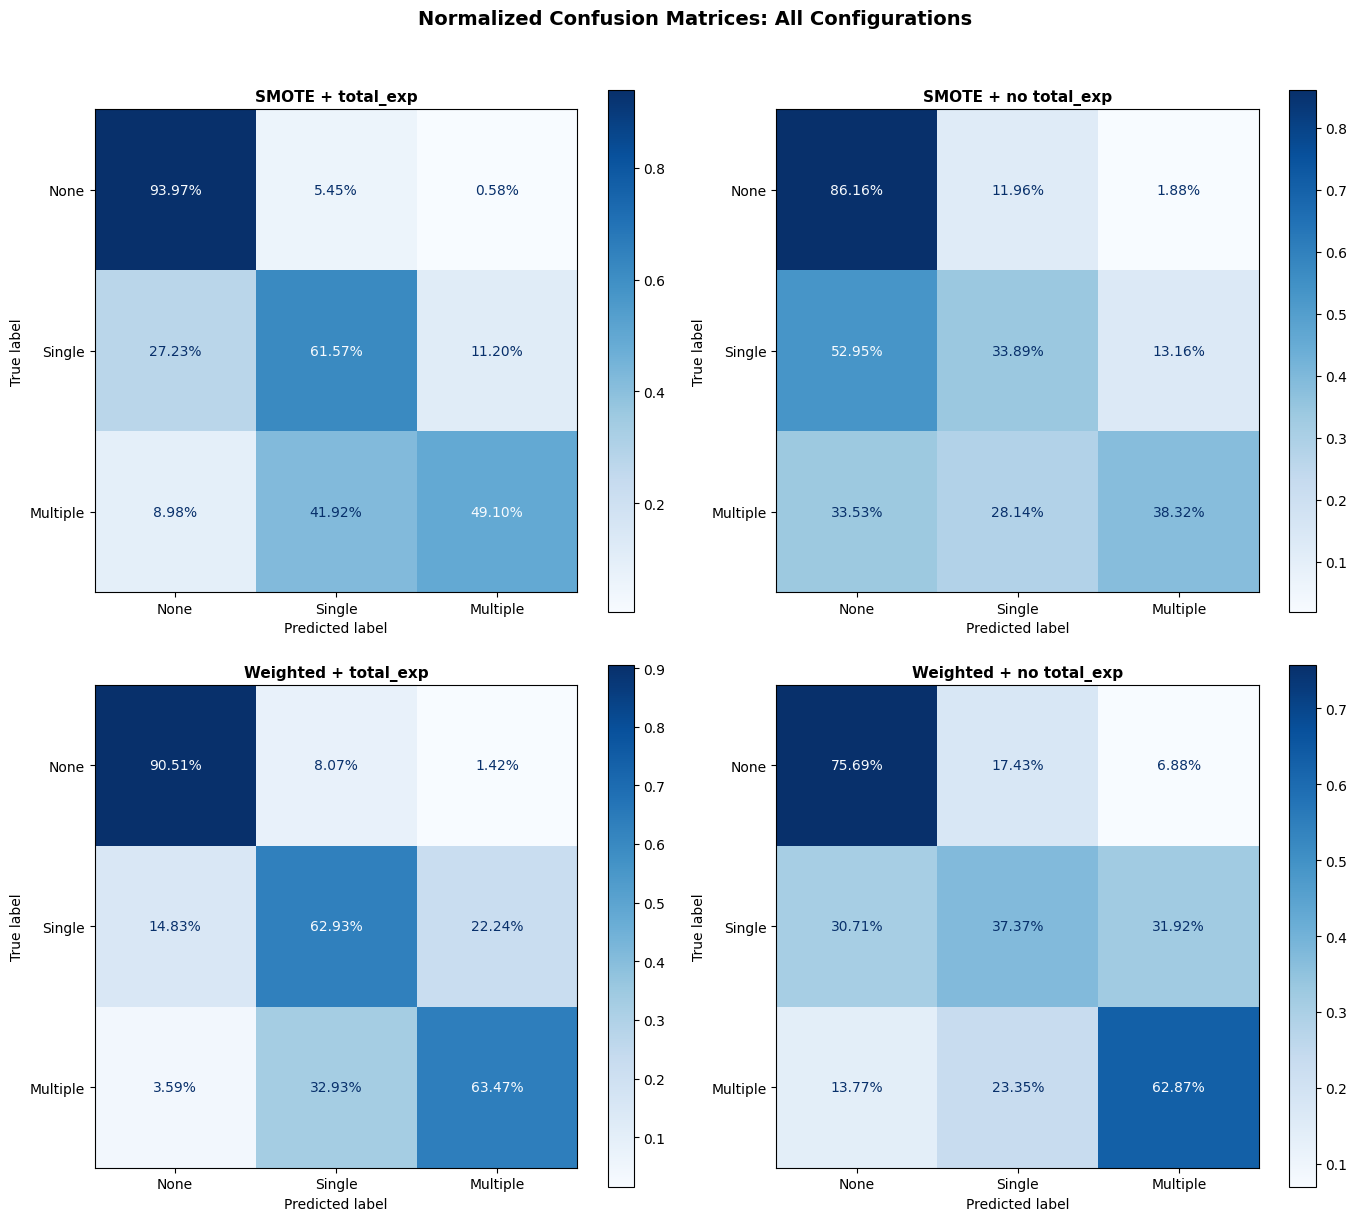

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

config_names = [r['config'] for r in results_list]
class_order = ['None', 'Single', 'Multiple']

for idx, (r, ax) in enumerate(zip(results_list, axes.flat)):
    cm = confusion_matrix(y_test, r['y_pred'], labels=class_order)
    cm_norm = confusion_matrix(y_test, r['y_pred'], labels=class_order, normalize='true')

    ConfusionMatrixDisplay(cm_norm, display_labels=class_order).plot(
        ax=ax, cmap='Blues', values_format='.2%')
    ax.set_title(f"{r['config']}", fontweight='bold', fontsize=11)

plt.suptitle('Normalized Confusion Matrices: All Configurations',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Saving the best model and wrap up Notebook 1**

In [27]:
import os
os.makedirs("outputs", exist_ok=True)
import pickle

best_model = results_list[3]  # Config 4

# Fit the scaler on the same training columns Config 4 used, so the saved model can be reused
scaled_cols = ['age', 'er_visits', 'num_conditions', 'num_unique_meds',
               'health_status_num', 'mental_health_num', 'poverty_cat_num']
fitted_scaler = StandardScaler().fit(X_no_exp_train[scaled_cols])

# saving the comparison table for the report
comparison_df.to_csv('outputs/logreg_comparison.csv', index=False)

# Save Config 4 model artifacts
artifacts = {
    'model': best_model['model'],
    'scaler': fitted_scaler,
    'scaled_columns': scaled_cols,
    'feature_names': X_no_exp_train.columns.tolist(),
    'classes': best_model['classes'],
    'comparison_results': comparison_df.to_dict()
}

with open('outputs/model1_logreg_final.pkl', 'wb') as f:
    pickle.dump(artifacts, f)

print("Saved comparison table and model artifacts to outputs/")
print(f"\nChosen configuration: {best_model['config']}")
print(f"  Macro AUC: {best_model['macro_auc']:.4f}")
print(f"  Macro F1:  {best_model['macro_f1']:.4f}")

Saved comparison table and model artifacts to outputs/

Chosen configuration: Weighted + no total_exp
  Macro AUC: 0.8071
  Macro F1:  0.4096


In [28]:
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()


Loaded 53,140 rows and 31 columns


   DUPERSID  panel  hospitalized  hosp_class  age  female   race region  \
0  40001013      6             0           0   71       0  White  South   
1  40001020      6             0           0   66       1  White  South   
2  40007015      6             0           0   40       0  Other  South   
3  40010015      6             0           0   41       0  White   West   
4  40010022      6             0           0   41       1  White   West   

   married insurance  ... has_depression  has_arthritis has_stroke  \
0      1.0    Public  ...              0              0          0   
1      1.0    Public  ...              0              0          0   
2      0.0   Private  ...              1              0          0   
3      1.0   Private  ...              0              0          0   
4      1.0   Private  ...              0              0          0   

  num_conditions  num_unique_meds  polypharmacy  hosp_class_label  \
0              1                5             1            